# Numerical final selection

Applies completeness, multi-method support and redundancy rules to the candidate scores, then checks city stability, profiles retained features and plots their distributions against asking rent.

**Project step:** §4.2 step 1.0.

**Inputs:** `outputs/03_phase_01_feature_selection_numerical{suffix}.csv` and `data/master_listing.parquet`.

**Outputs:** `outputs/05_phase_01_numerical_final_features{suffix}.csv`, `outputs/05_phase_01_numerical_profile{suffix}.csv`, `outputs/05_phase_01_numerical_gini_by_city{suffix}.csv`, `outputs/05_phase_01_numerical_histograms{suffix}.png`, and `outputs/05_phase_01_numerical_target_by_decile{suffix}.png`.

**Run after:** 03_feature_selection_numerical.

**Runtime:** ~5 min.


In [1]:
# ---- Data ----
INPUT = "data/master_listing.parquet"   # relative to the repo root
OUTPUT_DIR = "outputs"                  # every CSV / XLSX / PNG goes here

# ---- Filters (None = no filter) ----
CITY = None             # "chicago", "dfw", "dc", or a list of them       -> column `market`
NEIGHBORHOOD = None     # submarket or list -> `market_building__submarket`
START_DATE = None       # "YYYY-MM-DD": keep listings with DATE_COLUMN >= START_DATE
END_DATE = None         # "YYYY-MM-DD": keep listings with DATE_COLUMN <= END_DATE
DATE_COLUMN = "market_unit__enter_market"

# ---- Selection ----
MIN_COMPLETENESS = 50
MIN_METHODS = 2
GINI_MIN = 0.10
GB_MIN = 0.001
REDUNDANT = 0.9
METHOD = "spearman"
TARGET = "market_price_observation__first_asking_rent"
ANSWER_KEY = "truth_floorplan_market_rent__true_market_rent_at_enter"


In [2]:
from pathlib import Path

import pandas as pd

BLUE, GREEN, YELLOW, RED, BOLD, RESET = "\033[94m", "\033[92m", "\033[93m", "\033[91m", "\033[1m", "\033[0m"


def step(msg):
    print(f"\n{BOLD}{BLUE}▶ {msg}{RESET}")


def done(msg):
    print(f"{GREEN}  ✓ {msg}{RESET}")


def note(msg):
    print(f"{YELLOW}  • {msg}{RESET}")


ROOT = Path.cwd()
while not (ROOT / "data" / "master_listing.parquet").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
MASTER = ROOT / INPUT
CATALOG = ROOT / "data" / "master_columns.csv"
OUTPUTS = ROOT / OUTPUT_DIR
OUTPUTS.mkdir(parents=True, exist_ok=True)
NN = 5
FILTER_COLUMNS = ["market", "market_building__submarket", DATE_COLUMN]


def _as_list(value):
    """Normalize one filter value or a list of values."""
    if value is None:
        return None
    return [value] if isinstance(value, str) else list(value)


def suffix():
    """Build the shared output suffix from the active filters."""
    parts = []
    if CITY is not None:
        parts.append("+".join(map(str, _as_list(CITY))))
    if NEIGHBORHOOD is not None:
        parts.append("+".join(map(str, _as_list(NEIGHBORHOOD))))
    if START_DATE is not None or END_DATE is not None:
        parts.append(f"{START_DATE or 'start'}_to_{END_DATE or 'end'}")
    return "" if not parts else "__" + "__".join(parts)


def out(name, ext="csv"):
    """Build an output path with this notebook's number and active filters."""
    return OUTPUTS / f"{NN:02d}_phase_01_{name}{suffix()}.{ext}"


def upstream(number, name, ext="csv"):
    """Build an upstream notebook's output path with the active filters."""
    return OUTPUTS / f"{number:02d}_phase_01_{name}{suffix()}.{ext}"


def need(path, notebook):
    """Raise a clear instruction when a required upstream output is missing."""
    if not Path(path).exists():
        raise FileNotFoundError(f"Run {notebook} first; missing {path}")


def load(columns):
    """Read requested master columns and apply the configured listing filters."""
    requested = list(dict.fromkeys(columns))
    read_columns = list(dict.fromkeys(requested + FILTER_COLUMNS))
    frame = pd.read_parquet(MASTER, columns=read_columns)
    valid_values = {
        column: sorted(frame[column].dropna().astype(str).unique())
        for column in ("market", "market_building__submarket")
    }
    for column, value, label in (
        ("market", CITY, "city"),
        ("market_building__submarket", NEIGHBORHOOD, "neighborhood"),
    ):
        if value is not None:
            wanted = list(map(str, _as_list(value)))
            valid = valid_values[column]
            unknown = sorted(set(wanted) - set(valid))
            if unknown:
                raise ValueError(f"Unknown {label}(s) {unknown}. Valid values: {valid}")
            before = len(frame)
            frame = frame[frame[column].astype(str).isin(wanted)]
            note(f"{label}: {before:,} → {len(frame):,} rows")
    if START_DATE is not None:
        before = len(frame)
        frame = frame[frame[DATE_COLUMN] >= pd.Timestamp(START_DATE)]
        note(f"start date: {before:,} → {len(frame):,} rows")
    if END_DATE is not None:
        before = len(frame)
        frame = frame[frame[DATE_COLUMN] <= pd.Timestamp(END_DATE)]
        note(f"end date: {before:,} → {len(frame):,} rows")
    return frame[requested]


## Decisions and redundancy

Features are dropped first for completeness, then for method support. Correlations use pairwise-complete filtered rows. Among redundant survivors, the lower gradient-boosting feature is removed.

In [3]:
import math

import matplotlib.pyplot as plt
import numpy as np

SELECTION_PATH = upstream(3, "feature_selection_numerical")
need(SELECTION_PATH, "03_feature_selection_numerical")
step(f"Reading {SELECTION_PATH.relative_to(ROOT)}")
selection = pd.read_csv(SELECTION_PATH)
done(f"{len(selection)} numerical candidates")
features = selection["feature"].tolist()
frame = load(features + [TARGET, "market"])


def gini(x, y):
    """Normalized Gini of ordering y by x.

    Sort by x from high to low, take the Gini of the Lorenz curve of cumulative y, and divide by
    the Gini of the perfect ordering (y by itself). Tied x values are taken as one block, so a
    feature with few distinct values (bed, bath) is not scored on an arbitrary tie order.
    """
    def lorenz_gini(key):
        g = pd.DataFrame({"k": key, "y": y}).groupby("k")["y"].agg(["size", "sum"]).iloc[::-1]
        px = np.r_[0, g["size"].cumsum() / len(y)]
        py = np.r_[0, g["sum"].cumsum() / y.sum()]
        return 2 * ((py[1:] + py[:-1]) / 2 * np.diff(px)).sum() - 1
    return lorenz_gini(x) / lorenz_gini(y)


selection["n_methods"] = (
    (selection["gini"].abs() >= GINI_MIN).astype(int)
    + (selection["gradient_boosting"] > GB_MIN).astype(int)
    + (selection["lasso"].fillna(0) != 0).astype(int)
)
selection["redundant_with"] = ""
selection["decision"] = "keep"
selection["reason"] = "keep"
selection["note"] = ""

look_ahead_features = [
    "market_building__avg_price_change",
    "market_building__count_prices",
    "market_building__avg_price_duration_days",
    "market_building__avg_time_on_market_days",
]
look_ahead_note = "building-level average over the whole history; in a backtest it includes the future"
selection.loc[selection["feature"].isin(look_ahead_features), "note"] = look_ahead_note

step("Applying completeness and multi-method rules")
complete_enough = selection["completeness_pct"] > MIN_COMPLETENESS
methods_enough = selection["n_methods"] >= MIN_METHODS
for row_index, row in selection.iterrows():
    if row["completeness_pct"] <= MIN_COMPLETENESS:
        reason = f"drop: completeness {row['completeness_pct']:.1f}% <= {MIN_COMPLETENESS}%"
        selection.loc[row_index, ["decision", "reason"]] = ["drop", reason]
    elif row["n_methods"] < MIN_METHODS:
        reason = f"drop: kept by {row['n_methods']} of 3 methods"
        selection.loc[row_index, ["decision", "reason"]] = ["drop", reason]
survivors = set(selection.loc[selection["decision"].eq("keep"), "feature"])
done(f"{len(survivors)} pass both rules")

step(f"Checking redundancy among {len(survivors)} survivors with {METHOD}")
ordered_survivors = sorted(survivors)
correlations = frame[ordered_survivors].corr(method=METHOD, min_periods=2)
importance = selection.set_index("feature")["gradient_boosting"]
pairs = []
for first_index, first in enumerate(ordered_survivors):
    for second in ordered_survivors[first_index + 1:]:
        value = correlations.loc[first, second]
        if pd.notna(value) and abs(value) >= REDUNDANT:
            pairs.append((float(value), first, second))
pairs.sort(key=lambda pair: abs(pair[0]), reverse=True)
for correlation, first, second in pairs:
    if first not in survivors or second not in survivors:
        continue
    if importance[first] < importance[second]:
        dropped, kept = first, second
    else:
        dropped, kept = second, first
    survivors.remove(dropped)
    row_index = selection.index[selection["feature"].eq(dropped)][0]
    reason = (f"drop: redundant with {kept} (rho={correlation:+.2f}), "
              "lower GB importance")
    selection.loc[row_index, ["decision", "reason", "redundant_with"]] = ["drop", reason, kept]
    print(f"{RED}  ✗ {dropped} (rho={correlation:+.2f}); kept {kept}{RESET}")
final = selection[selection["feature"].isin(survivors)].copy()
selection.to_csv(out("numerical_final_features"), index=False)
done(f"Wrote all {len(selection)} candidate decisions to {out('numerical_final_features').name}")


Matplotlib is building the font cache; this may take a moment.



▶ Reading outputs/03_phase_01_feature_selection_numerical.csv
  ✓ 44 numerical candidates



▶ Applying completeness and multi-method rules
  ✓ 17 pass both rules

▶ Checking redundancy among 17 survivors with spearman


  ✗ market_unit__bed (rho=+0.92); kept market_unit__sqft
  ✓ Wrote all 44 candidate decisions to 05_phase_01_numerical_final_features.csv


## City stability and feature profile

For each retained feature, Gini is calculated within each city. `max_minus_min` is the difference between its largest and smallest city Gini; a large spread means the feature works differently by city.

In [4]:
step("Gini by city")
cities = sorted(frame["market"].dropna().unique())
city_results = []
for feature in final["feature"]:
    row = {"feature": feature}
    values = []
    for city in cities:
        city_frame = frame[frame["market"].eq(city)]
        present = city_frame[feature].notna() & city_frame[TARGET].notna()
        value = gini(city_frame.loc[present, feature].to_numpy(),
                     city_frame.loc[present, TARGET].to_numpy())
        row[city] = value
        values.append(value)
    finite_values = [value for value in values if np.isfinite(value)]
    row["max_minus_min"] = max(finite_values) - min(finite_values) if finite_values else np.nan
    city_results.append(row)
gini_by_city = pd.DataFrame(city_results, columns=["feature"] + cities + ["max_minus_min"])
gini_by_city.round(4).to_csv(out("numerical_gini_by_city"), index=False)
done(f"Wrote {len(gini_by_city)} feature rows")
gini_by_city.round(4)

step("Profiling retained features")
profile_rows = []
for feature in final["feature"]:
    values = frame[feature].dropna()
    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    spread = q3 - q1
    outlier_mask = (values < q1 - 1.5 * spread) | (values > q3 + 1.5 * spread)
    profile_rows.append({
        "feature": feature,
        "n": len(values),
        "missing_pct": frame[feature].isna().mean() * 100,
        "mean": values.mean(),
        "std": values.std(),
        "min": values.min(),
        "p01": values.quantile(0.01),
        "p25": q1,
        "median": values.median(),
        "p75": q3,
        "p99": values.quantile(0.99),
        "max": values.max(),
        "skew": values.skew(),
        "outlier_pct": outlier_mask.mean() * 100,
    })
profile_columns = ["feature", "n", "missing_pct", "mean", "std", "min", "p01", "p25",
                   "median", "p75", "p99", "max", "skew", "outlier_pct"]
profile = pd.DataFrame(profile_rows, columns=profile_columns)
profile.to_csv(out("numerical_profile"), index=False)
done(f"Wrote {len(profile)} feature profiles")
profile.round(3)



▶ Gini by city


  ✓ Wrote 16 feature rows

▶ Profiling retained features


  ✓ Wrote 16 feature profiles


,feature,n,missing_pct,mean,std,min,p01,p25,median,p75,p99,max,skew,outlier_pct
0,market_unit__sqft,925743,4.332,914.823,285.544,415.000,470.000,695.000,850.000,1115.000,1695.000,2155.000,0.747,0.592
1,market_building__lat,967661,0.000,38.554,3.924,32.729,32.736,32.960,38.992,41.894,42.044,42.052,-0.617,0.000
2,market_building__n_building_amenities,801127,17.210,21.663,7.782,2.000,6.000,18.000,18.000,30.000,30.000,30.000,-0.200,0.000
3,market_building__lon,967661,0.000,-88.358,6.953,-97.363,-97.349,-96.784,-87.662,-87.624,-76.993,-76.986,0.305,0.000
4,market_building__year_built,863321,10.783,1987.326,36.152,1890.000,1893.000,1964.000,1999.000,2020.000,2025.000,2026.000,-0.918,0.000
5,market_building__avg_price_change,967661,0.000,-0.712,2.310,-21.320,-9.900,-1.270,-0.450,0.150,4.180,10.750,-2.336,12.445
6,market_building__avg_time_on_market_days,967572,0.009,51.828,22.713,27.380,31.340,38.150,41.420,62.700,119.620,506.750,2.438,3.288
7,market_building__n_unit_amenities,801127,17.210,14.656,5.256,3.000,5.000,10.000,14.000,20.000,22.000,22.000,0.031,0.000
8,market_building__avg_review_score,967614,0.005,0.660,0.182,0.085,0.218,0.531,0.672,0.803,0.973,0.990,-0.353,0.081
9,market_unit__floor,490576,49.303,5.499,6.849,1.000,1.000,2.000,3.000,6.000,35.000,45.000,2.710,10.024



▶ Plotting retained feature distributions


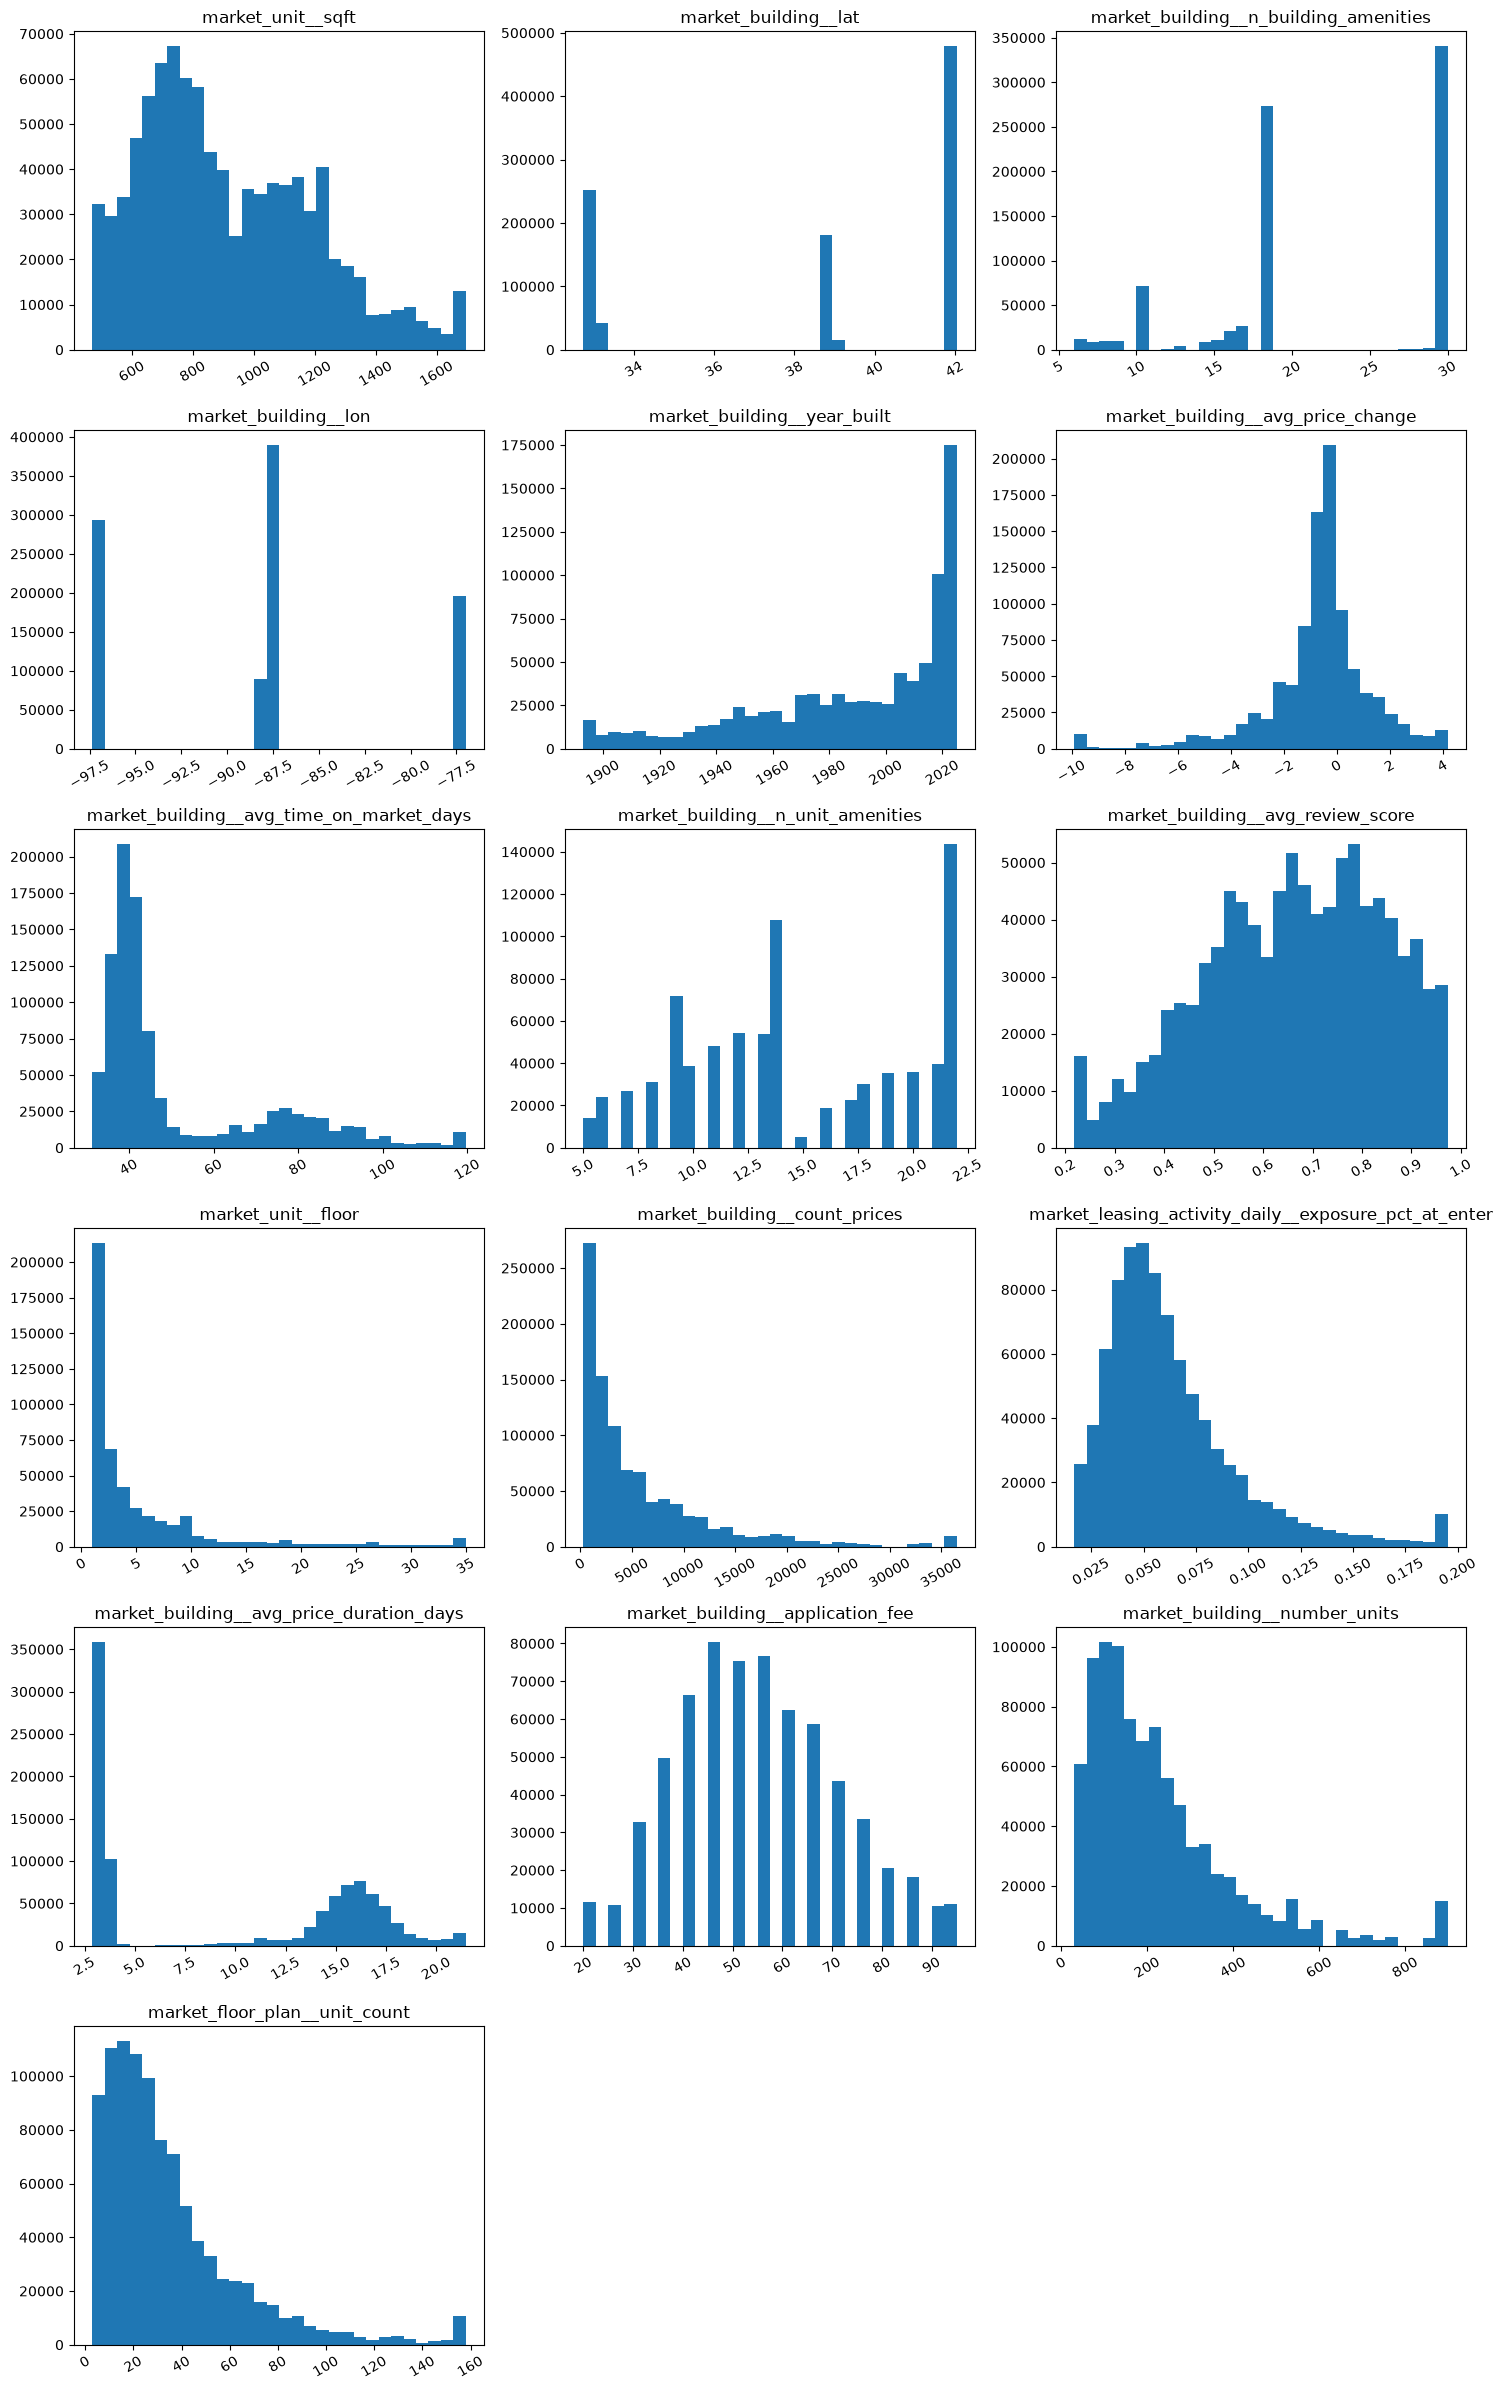


▶ Plotting mean asking rent by feature decile


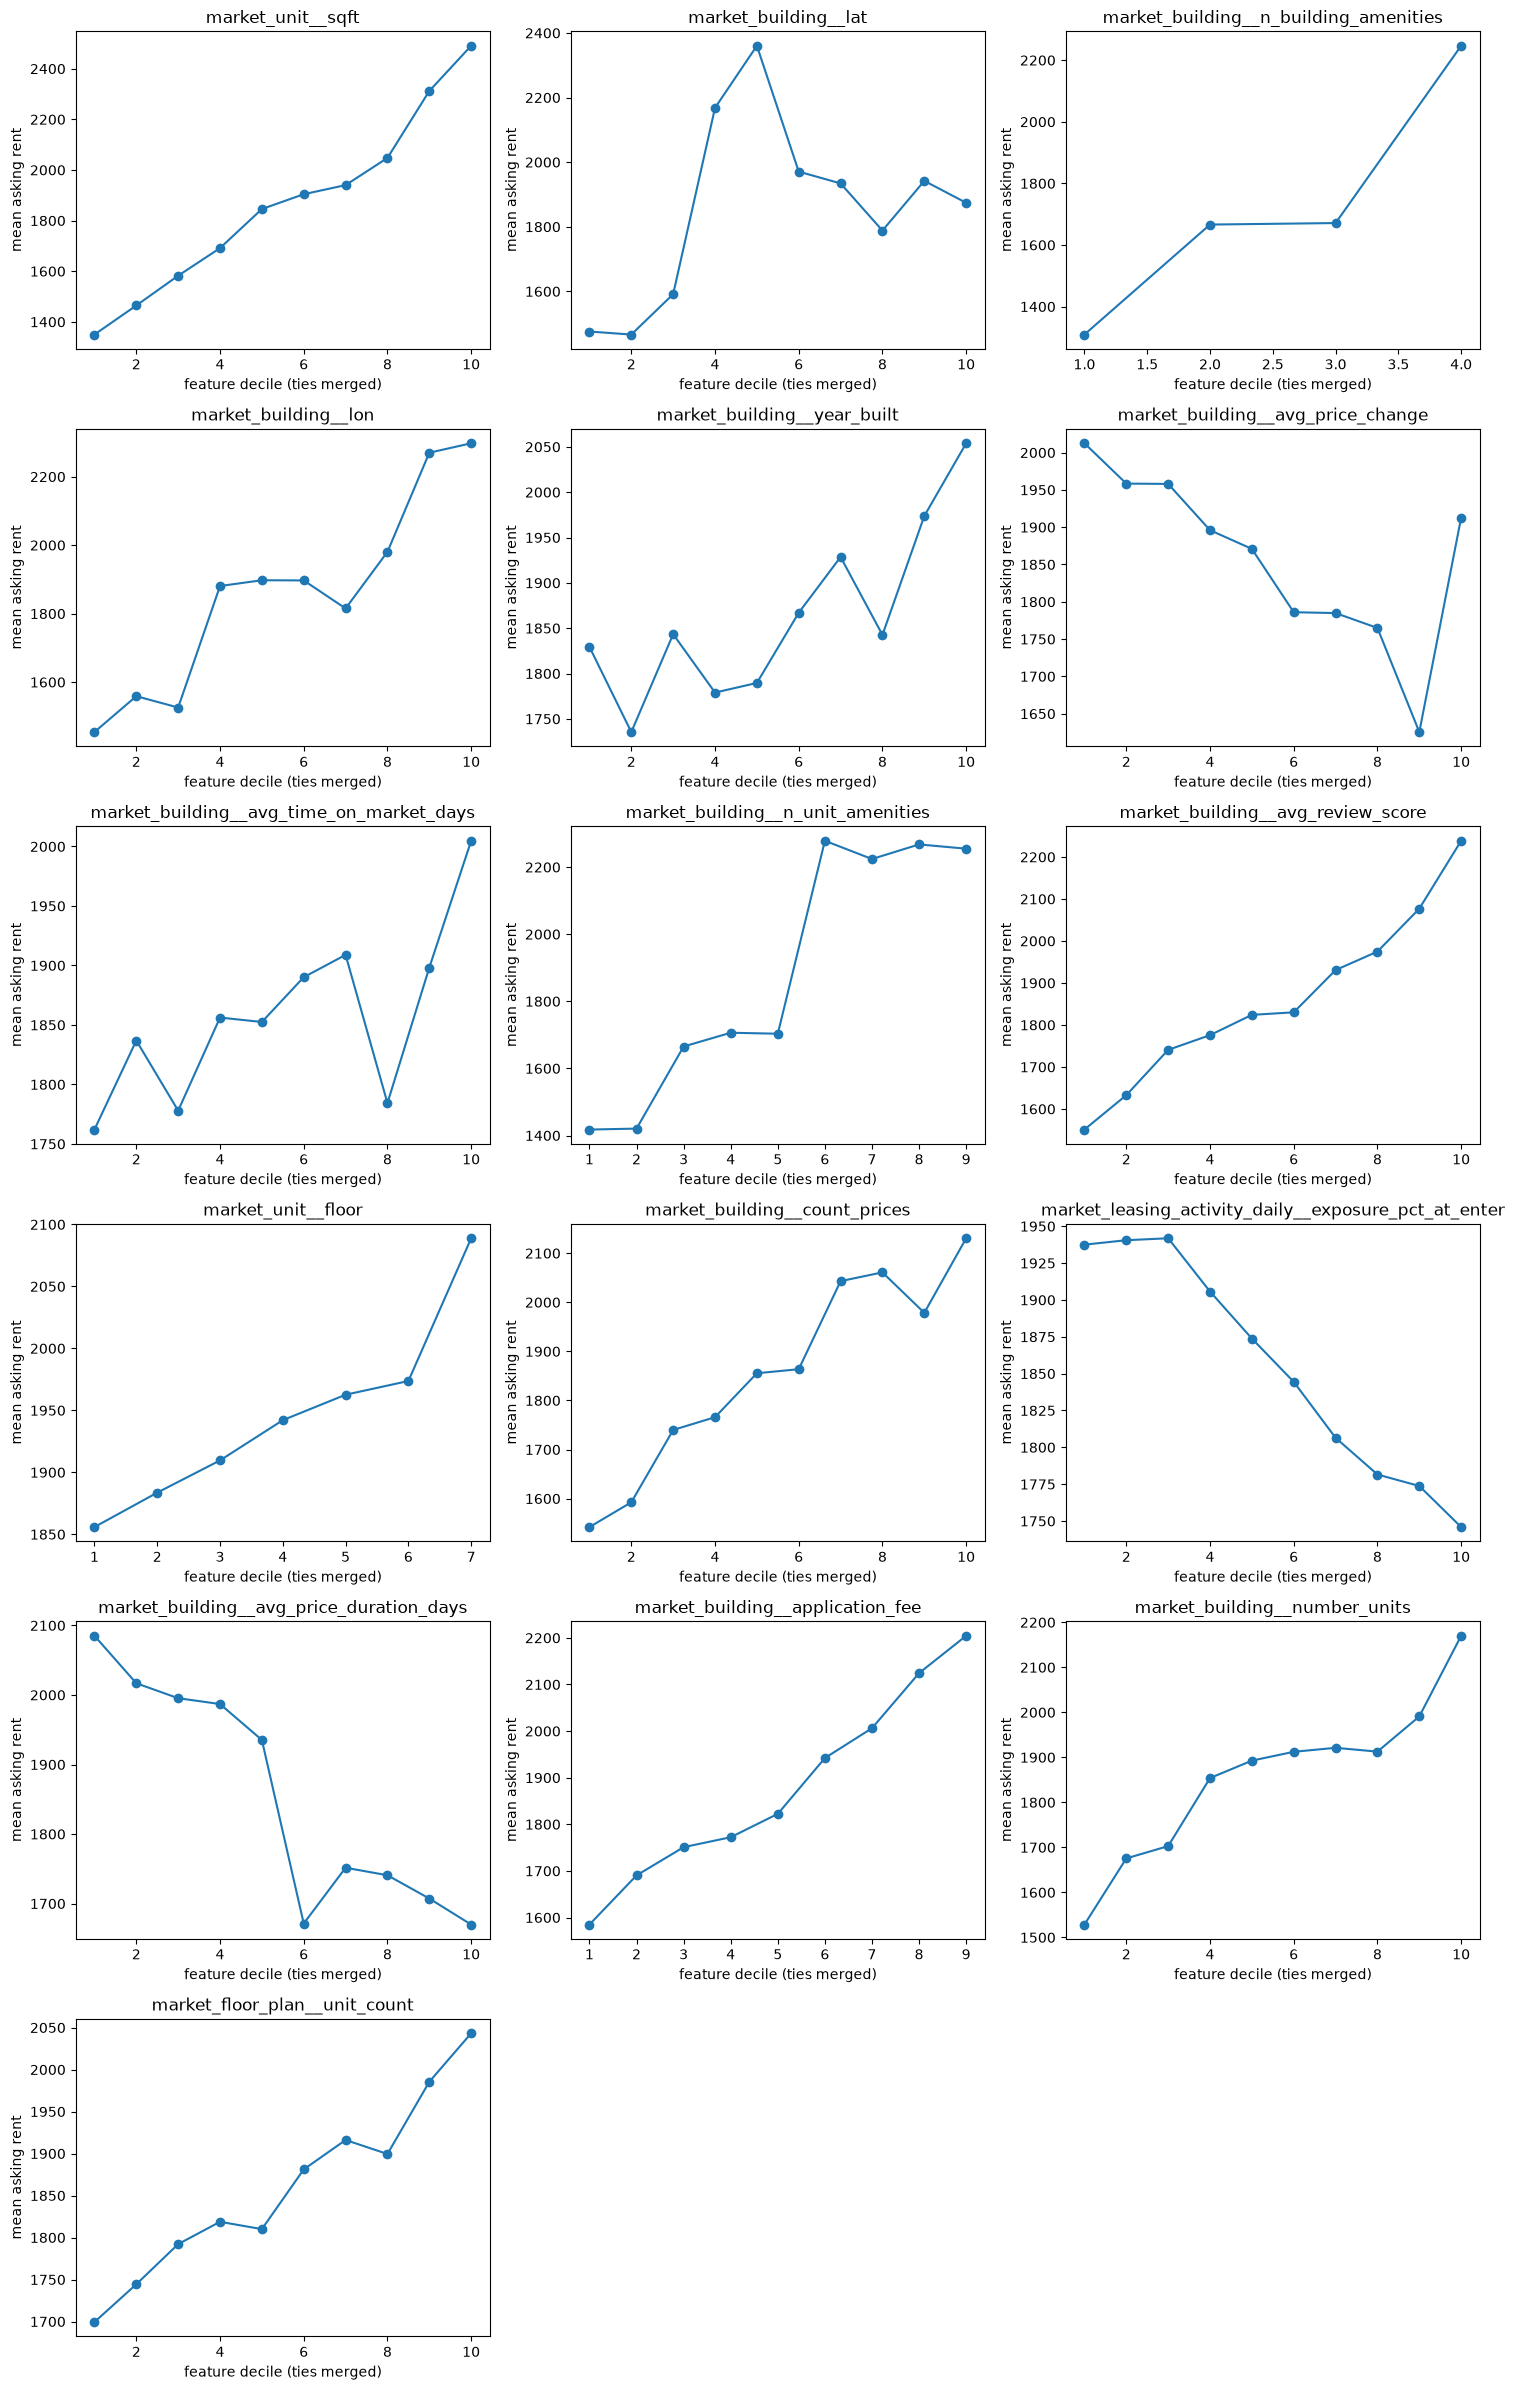

In [5]:
step("Plotting retained feature distributions")
kept_features = final["feature"].tolist()
column_count = 3
row_count = max(1, math.ceil(len(kept_features) / column_count))
figure, axes = plt.subplots(row_count, column_count, figsize=(15, 4 * row_count), squeeze=False)
flat_axes = axes.ravel()
for axis, feature in zip(flat_axes, kept_features):
    values = frame[feature].dropna()
    if not values.empty:
        axis.hist(values.clip(values.quantile(0.01), values.quantile(0.99)), bins=30)
    axis.set_title(feature)
    axis.tick_params(axis="x", labelrotation=30)
for axis in flat_axes[len(kept_features):]:
    axis.remove()
figure.tight_layout()
figure.savefig(out("numerical_histograms", "png"), dpi=150)
plt.show()

step("Plotting mean asking rent by feature decile")
figure, axes = plt.subplots(row_count, column_count, figsize=(15, 4 * row_count), squeeze=False)
flat_axes = axes.ravel()
for axis, feature in zip(flat_axes, kept_features):
    pair = frame[[feature, TARGET]].dropna().copy()
    if len(pair) >= 2 and pair[feature].nunique() >= 2:
        pair["decile"] = pd.qcut(pair[feature], 10, duplicates="drop")
        means = pair.groupby("decile", observed=True)[TARGET].mean()
        axis.plot(range(1, len(means) + 1), means.to_numpy(), marker="o")
    axis.set_title(feature)
    axis.set_xlabel("feature decile (ties merged)")
    axis.set_ylabel("mean asking rent")
for axis in flat_axes[len(kept_features):]:
    axis.remove()
figure.tight_layout()
figure.savefig(out("numerical_target_by_decile", "png"), dpi=150)
plt.show()


In [6]:
step("Final funnel")
counts = [
    len(selection),
    int(complete_enough.sum()),
    int((complete_enough & methods_enough).sum()),
    len(final),
]
labels = ["candidates", "complete enough", f"≥ {MIN_METHODS} methods", "final"]
for label, count in zip(labels, counts):
    color = GREEN if count / max(len(selection), 1) >= 0.5 else YELLOW if count else RED
    print(f"  {label:24s}{color}{'█' * round(40 * count / max(len(selection), 1)):40s} {count:>4}{RESET}")

step("Final numerical feature list")
for row in final.itertuples():
    print(f"{GREEN}  ✓ {row.feature}{RESET} gini {row.gini:+.3f}  "
          f"gb {row.gradient_boosting:.4f}  lasso {row.lasso:+.2f}  "
          f"answer-key Gini {row.gini_answer_key:+.3f}")
final[["source_table", "feature", "completeness_pct", "gini", "gradient_boosting",
       "lasso", "gini_answer_key", "n_methods", "redundant_with", "decision", "reason", "note"]]



▶ Final funnel
  candidates              ████████████████████████████████████████   44
  complete enough         █████████████████████████████              32
  ≥ 2 methods             ███████████████                            17
  final                   ███████████████                            16

▶ Final numerical feature list
  ✓ market_unit__sqft gini +0.538  gb 0.3596  lasso +306.23  answer-key Gini +0.542
  ✓ market_building__lat gini +0.191  gb 0.2814  lasso +0.00  answer-key Gini +0.188
  ✓ market_building__n_building_amenities gini +0.509  gb 0.1958  lasso +156.45  answer-key Gini +0.505
  ✓ market_building__lon gini +0.395  gb 0.1411  lasso +278.78  answer-key Gini +0.402
  ✓ market_building__year_built gini +0.106  gb 0.0534  lasso +73.08  answer-key Gini +0.113
  ✓ market_building__avg_price_change gini -0.124  gb 0.0153  lasso -19.55  answer-key Gini -0.126
  ✓ market_building__avg_time_on_market_days gini +0.078  gb 0.0121  lasso +38.95  answer-key Gini +0.032
  ✓ ma

,source_table,feature,completeness_pct,gini,gradient_boosting,lasso,gini_answer_key,n_methods,redundant_with,decision,reason,note
0,market_unit,market_unit__sqft,95.67,0.5376,0.3596,306.23,0.5425,3,,keep,keep,
1,market_building,market_building__lat,100.00,0.1906,0.2814,0.00,0.1883,2,,keep,keep,
2,market_building,market_building__n_building_amenities,82.79,0.5090,0.1958,156.45,0.5055,3,,keep,keep,
3,market_building,market_building__lon,100.00,0.3951,0.1411,278.78,0.4019,3,,keep,keep,
4,market_building,market_building__year_built,89.22,0.1063,0.0534,73.08,0.1129,3,,keep,keep,
6,market_building,market_building__avg_price_change,100.00,-0.1244,0.0153,-19.55,-0.1261,3,,keep,keep,building-level average over the whole history;...
7,market_building,market_building__avg_time_on_market_days,99.99,0.0778,0.0121,38.95,0.0316,2,,keep,keep,building-level average over the whole history;...
9,market_building,market_building__n_unit_amenities,82.79,0.5015,0.0101,36.86,0.4964,3,,keep,keep,
10,market_building,market_building__avg_review_score,100.00,0.3003,0.0088,39.90,0.3033,3,,keep,keep,
11,market_unit,market_unit__floor,50.70,0.0999,0.0059,31.10,0.0785,2,,keep,keep,


## How to read this

These results come from synthetic data, so they check the method and are not a final feature list. As described in `docs/project_phases.md` §2, synthetic data can test recovery of known truth but cannot establish the final feature list or real-world accuracy.